# Fertilizer & Deficiency Model Training

**Module 2: ML Soil Classification & Analysis Engine**

Implements the project documentation requirement (page 2):

> "Develop a **gradient-boosted classification model** using structured soil test data to
> predict **nutrient deficiency categories**."

## What this notebook produces

| Artifact | Purpose |
|---|---|
| `deficiency_{n,p,k,ph}_xgb.json` | Per-nutrient deficiency classifiers |
| `deficiency_label_encoders.joblib` | Class labels for the above |
| `fertilizer_xgb.json` | 10-class fertilizer advisory model |
| `fertilizer_label_encoder.joblib` | Class labels for the above |
| `fertilizer_remarks.json` | Fertilizer → farmer-facing advisory text |
| `structured_model_meta.json` | Feature order, thresholds, medians, metrics, caveats |

Everything is written to `models/structured/` and loaded at inference time by
`backend/app/ml/structured.py`, which serves `POST /analyze`.

---

## Two things to read before trusting the numbers

**1. Why this dataset.** We train on `fertilizer_recommendation.csv`, *not*
`crop_recommendation.csv`. The documentation mandates **six** structured parameters — NPK,
pH, organic matter, moisture. Only the fertilizer dataset carries all six (`Carbon` →
organic matter, `Moisture` → moisture). The crop dataset has neither of those two columns,
so two of the six required inputs would be collected from farmers and then silently
ignored by the model.

**2. The deficiency models will score ~99%, and that is *not* a good result.** No available
dataset carries ground-truth nutrient-deficiency labels, so the labels here are **derived**
from agronomic threshold bands. The classifiers are therefore relearning a deterministic
if-else rule, not discovering agronomy. They are trained because the documentation asks for
a gradient-boosted deficiency model, and because they add calibrated probabilities and SHAP
attributions that raw rules cannot provide. **The rule engine stays the production source of
truth.**

The **fertilizer model is the genuinely predictive one** — its 10 classes are real labels
from the dataset, so its score measures actual skill.

## 1. Imports and Configuration

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Fixed seed everywhere so the split and the trees are reproducible run to run.
RANDOM_STATE = 42

# Notebooks have no __file__, so resolve the repo root from the working directory.
# This works whether Jupyter was started in notebooks/ or at the repo root.
CWD = Path.cwd()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

DATA_PATH = REPO_ROOT / "data" / "fertilizer_recommendation.csv"
MODELS_DIR = REPO_ROOT / "models" / "structured"
MODELS_DIR.mkdir(exist_ok=True)

print("repo root :", REPO_ROOT)
print("dataset   :", DATA_PATH.name, "| exists:", DATA_PATH.is_file())
print("models to :", MODELS_DIR)

repo root : C:\Users\shash\AI-Based-Soil-Health-Assessment-System-for-Nutrient-Deficiency-Detection---Crop-Recommend-July-2026
dataset   : fertilizer_recommendation.csv | exists: True
models to : C:\Users\shash\AI-Based-Soil-Health-Assessment-System-for-Nutrient-Deficiency-Detection---Crop-Recommend-July-2026\models\structured


## 2. Feature Contract and Agronomic Thresholds

`FEATURES` is the **canonical feature order**. The API must supply values in exactly this
order — reads the order back from
`structured_model_meta.json` and builds its input row from it. Reordering this list without
retraining would silently feed nitrogen into the phosphorus slot.

The threshold bands are the single source of truth for deficiency labelling. They are
mirrored in the inference service, so **changing them here requires a retrain** plus a
matching edit there.

In [2]:
# The six parameters named in the project documentation (page 2).
FEATURES = [
    "nitrogen",        # kg/ha
    "phosphorus",      # kg/ha
    "potassium",       # kg/ha
    "ph",              # 0-14
    "organic_matter",  # %  (dataset column: Carbon)
    "moisture",        # %  (dataset column: Moisture, stored 0-1 -> scaled to %)
]

# Dataset column -> our canonical snake_case name.
# Note the dataset spells it "Phosphorous"; we normalise to "phosphorus".
COLUMN_MAP = {
    "Nitrogen": "nitrogen",
    "Phosphorous": "phosphorus",
    "Potassium": "potassium",
    "PH": "ph",
    "Carbon": "organic_matter",
    "Moisture": "moisture",
    "Fertilizer": "fertilizer",
    "Remark": "remark",
}

# Agronomic threshold bands (kg/ha for NPK).
# PROVISIONAL: calibrate against ICAR Soil Health Card reference bands for the target
# region before using these for real advisory output.
THRESHOLDS = {
    "nitrogen": {"low": 40.0, "high": 80.0},
    "phosphorus": {"low": 30.0, "high": 60.0},
    "potassium": {"low": 30.0, "high": 60.0},
}
PH_BANDS = {"acidic": 6.0, "alkaline": 7.5}

print("features :", FEATURES)
print("NPK bands:", THRESHOLDS)
print("pH bands : acidic < 6.0 | neutral 6.0-7.5 | alkaline > 7.5")

features : ['nitrogen', 'phosphorus', 'potassium', 'ph', 'organic_matter', 'moisture']
NPK bands: {'nitrogen': {'low': 40.0, 'high': 80.0}, 'phosphorus': {'low': 30.0, 'high': 60.0}, 'potassium': {'low': 30.0, 'high': 60.0}}
pH bands : acidic < 6.0 | neutral 6.0-7.5 | alkaline > 7.5


## 3. Labelling Rules

These two functions are the **authoritative** deficiency classifier — the models that follow
only annotate their output with confidence and SHAP.

In [3]:
def nutrient_status(value: float, low: float, high: float) -> str:
    # Classify a nutrient concentration against its agronomic band.
    if value < low:
        return "low"
    if value > high:
        return "high"
    return "adequate"


def ph_status(value: float) -> str:
    # Classify soil reaction (acidity / alkalinity).
    if value < PH_BANDS["acidic"]:
        return "acidic"
    if value > PH_BANDS["alkaline"]:
        return "alkaline"
    return "neutral"


# Sanity-check the boundaries. Note the bands are exclusive at the edges:
# N=40 is "adequate" (not low), pH=6.0 is "neutral" (not acidic).
for v in (20, 40, 60, 80, 95):
    print(f"  N={v:>3} kg/ha -> {nutrient_status(v, 40.0, 80.0)}")
print()
for v in (5.1, 6.0, 6.8, 7.5, 8.4):
    print(f"  pH={v:<4}      -> {ph_status(v)}")

  N= 20 kg/ha -> low
  N= 40 kg/ha -> adequate
  N= 60 kg/ha -> adequate
  N= 80 kg/ha -> adequate
  N= 95 kg/ha -> high

  pH=5.1       -> acidic
  pH=6.0       -> neutral
  pH=6.8       -> neutral
  pH=7.5       -> neutral
  pH=8.4       -> alkaline


## 4. Load the Raw Dataset

In [4]:
raw = pd.read_csv(DATA_PATH)

print("shape:", raw.shape)
print("columns:", list(raw.columns))
raw.head()

shape: (3100, 12)
columns: ['Temperature', 'Moisture', 'Rainfall', 'PH', 'Nitrogen', 'Phosphorous', 'Potassium', 'Carbon', 'Soil', 'Crop', 'Fertilizer', 'Remark']


,Temperature,Moisture,Rainfall,PH,Nitrogen,Phosphorous,Potassium,Carbon,Soil,Crop,Fertilizer,Remark
0,50.179845,0.725893,205.600816,6.227358,66.701872,76.963560,96.429065,0.496300,Loamy Soil,rice,Compost,Enhances organic matter and improves soil stru...
1,21.633318,0.721958,306.081601,7.173131,71.583316,163.057636,148.128347,1.234242,Loamy Soil,rice,Balanced NPK Fertilizer,"Provides a balanced mix of nitrogen, phosphoru..."
2,23.060964,0.685751,259.336414,7.380793,75.709830,62.091508,80.308971,1.795650,Peaty Soil,rice,Water Retaining Fertilizer,Improves water retention in dry soils. Prefer ...
3,26.241975,0.755095,212.703513,6.883367,78.033687,151.012521,153.005712,1.517556,Loamy Soil,rice,Balanced NPK Fertilizer,"Provides a balanced mix of nitrogen, phosphoru..."
4,21.490157,0.730672,268.786767,7.578760,71.765123,66.257371,97.000886,1.782985,Peaty Soil,rice,Organic Fertilizer,"Enhances fertility naturally, ideal for peaty ..."


In [5]:
# Look at the ranges before cleaning -- several minimums are negative, which is the
# problem addressed in the next section.
raw.describe().T[["min", "25%", "50%", "75%", "max"]]

,min,25%,50%,75%,max
Temperature,4.011486,22.408505,26.132938,29.987887,56.653592
Moisture,0.227436,0.493595,0.599520,0.708575,0.972361
Rainfall,-85.709593,61.283985,96.485935,147.619401,411.955947
PH,3.448974,5.860489,6.337308,6.899739,9.562341
Nitrogen,35.527718,54.835715,59.429649,65.792790,98.581039
Phosphorous,-37.649739,43.039260,58.205269,86.108983,177.314481
Potassium,-20.509108,49.992405,58.710808,76.318626,161.067982
Carbon,-0.280560,0.956401,1.463357,2.003534,3.241984


## 5. Data Quality — Physically Impossible Values

The dataset carries synthetic Gaussian noise that pushed several columns **negative**. A
negative nutrient or carbon concentration cannot exist in soil.

These rows are **dropped, not clipped**. Clipping to zero would pile probability mass at a
single value and teach the model that zero-concentration soil is common; dropping simply
removes invalid observations. The cost is ~7% of the data, which is acceptable at 3,100 rows.

In [6]:
impossible = {}
for col in ["Nitrogen", "Phosphorous", "Potassium", "Carbon", "Rainfall", "PH", "Moisture"]:
    n = int((raw[col] < 0).sum())
    if n:
        impossible[col] = n

print("Rows containing negative (physically impossible) values:")
for col, n in impossible.items():
    print(f"  {col:<14} {n:>4} rows  ({100 * n / len(raw):.1f}%)")

# Unit mismatch: the dataset stores moisture as a fraction, our API contract uses percent.
print(
    f"\nMoisture is a 0-1 fraction in the source: "
    f"{raw['Moisture'].min():.3f} - {raw['Moisture'].max():.3f}"
)
print("It is scaled by 100 during cleaning to match the API contract (percent).")

Rows containing negative (physically impossible) values:
  Phosphorous      78 rows  (2.5%)
  Potassium        71 rows  (2.3%)
  Carbon           85 rows  (2.7%)
  Rainfall         75 rows  (2.4%)

Moisture is a 0-1 fraction in the source: 0.227 - 0.972
It is scaled by 100 during cleaning to match the API contract (percent).


## 6. Clean and Normalise

In [7]:
def load_and_clean() -> tuple[pd.DataFrame, dict]:
    # Load the dataset, normalise units, and drop physically impossible rows.
    df = pd.read_csv(DATA_PATH).rename(columns=COLUMN_MAP)
    n_raw = len(df)

    # Moisture: 0-1 fraction -> percent.
    df["moisture"] = df["moisture"] * 100.0

    # Keep only rows where every value is physically possible.
    physical = (
        (df["nitrogen"] >= 0)
        & (df["phosphorus"] >= 0)
        & (df["potassium"] >= 0)
        & (df["organic_matter"] >= 0)
        & (df["ph"].between(0, 14))
        & (df["moisture"].between(0, 100))
    )
    df = df[physical].copy()

    # Provenance record -- saved into the metadata so the artifacts carry their own history.
    report = {
        "rows_raw": n_raw,
        "rows_after_cleaning": len(df),
        "rows_dropped": n_raw - len(df),
        "drop_reason": "negative nutrient/carbon values or out-of-range pH/moisture",
    }
    return df, report


df, clean_report = load_and_clean()

print(f"rows raw     : {clean_report['rows_raw']}")
print(
    f"rows dropped : {clean_report['rows_dropped']} "
    f"({100 * clean_report['rows_dropped'] / clean_report['rows_raw']:.1f}%)"
)
print(f"rows used    : {clean_report['rows_after_cleaning']}")

# All minimums should now be >= 0.
df[FEATURES].describe().T[["min", "50%", "max"]]

rows raw     : 3100
rows dropped : 230 (7.4%)
rows used    : 2870


,min,50%,max
nitrogen,35.527718,59.429649,97.854559
phosphorus,12.445888,58.847927,177.314481
potassium,29.635327,59.136049,161.067982
ph,3.448974,6.338164,9.562341
organic_matter,0.248064,1.486759,3.241984
moisture,22.743613,60.033486,97.236121


## 7. Exploratory Analysis

Distributions with the agronomic bands overlaid. The dashed lines show where each nutrient
crosses from `low` → `adequate` → `high`, which makes it obvious how much of the data falls
in each class before we even derive the labels.

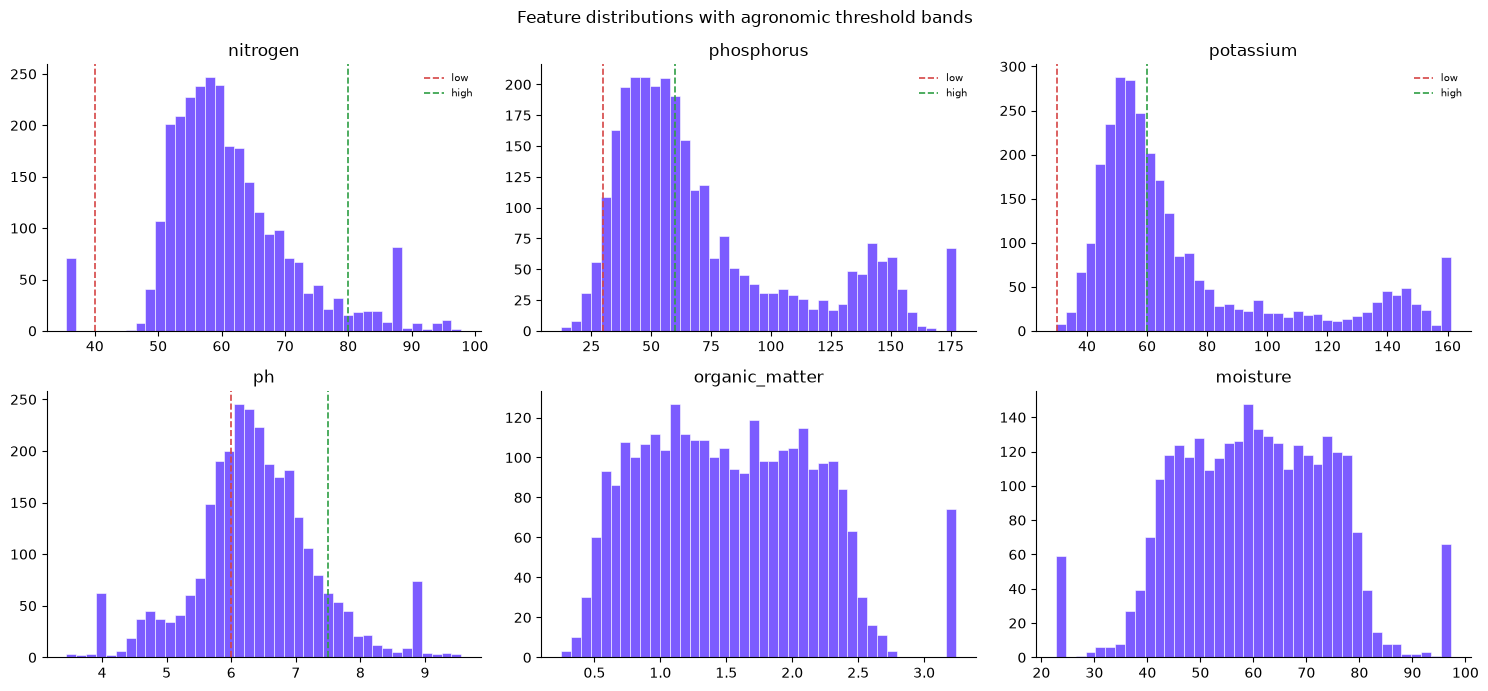

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for ax, col in zip(axes.flat, FEATURES):
    ax.hist(df[col], bins=40, color="#7c5cff", edgecolor="white", linewidth=0.4)
    ax.set_title(col)
    ax.spines[["top", "right"]].set_visible(False)

    # Overlay the threshold bands so class boundaries are visible.
    if col in THRESHOLDS:
        ax.axvline(THRESHOLDS[col]["low"], color="#d64545", ls="--", lw=1.2, label="low")
        ax.axvline(THRESHOLDS[col]["high"], color="#2f9e44", ls="--", lw=1.2, label="high")
        ax.legend(fontsize=7, frameon=False)
    elif col == "ph":
        ax.axvline(PH_BANDS["acidic"], color="#d64545", ls="--", lw=1.2)
        ax.axvline(PH_BANDS["alkaline"], color="#2f9e44", ls="--", lw=1.2)

fig.suptitle("Feature distributions with agronomic threshold bands", fontsize=12)
plt.tight_layout()
plt.show()

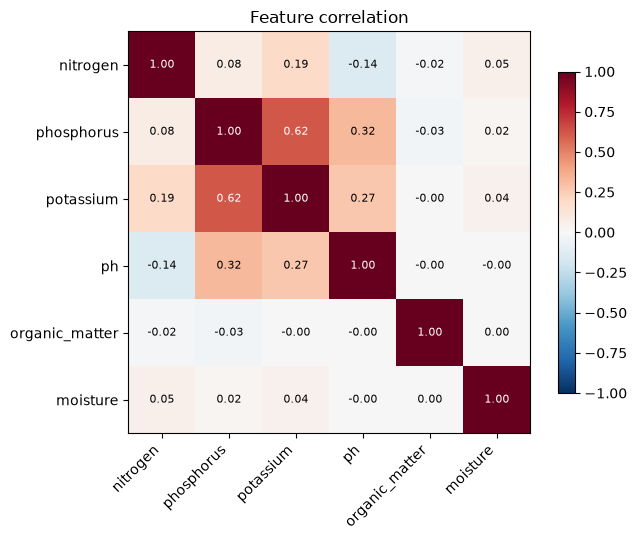

In [9]:
# Correlation matrix. Low inter-feature correlation here means each of the six parameters
# carries independent signal -- none is redundant.
corr = df[FEATURES].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)

for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        val = corr.iloc[i, j]
        ax.text(
            j, i, f"{val:.2f}", ha="center", va="center", fontsize=8,
            color="black" if abs(val) < 0.6 else "white",
        )

fig.colorbar(im, shrink=0.8)
ax.set_title("Feature correlation")
plt.tight_layout()
plt.show()

## 8. Derive Deficiency Labels

This is the step that makes the deficiency models' accuracy uninformative: the target becomes
a **deterministic function of the features**. A tree ensemble can recover an axis-aligned
threshold split almost perfectly, which is why ~99% is the expected — and unimpressive —
outcome.

We keep them because the documentation asks for a gradient-boosted deficiency model, and
because the probabilities and SHAP values they expose are genuinely useful on top of a
hard rule.

In [10]:
def derive_labels(df: pd.DataFrame) -> pd.DataFrame:
    # Attach deficiency category labels derived from the agronomic thresholds.
    for nutrient in ("nitrogen", "phosphorus", "potassium"):
        t = THRESHOLDS[nutrient]
        # Bind `t` as a default arg so the closure captures this iteration's value.
        df[f"{nutrient}_status"] = df[nutrient].apply(
            lambda v, t=t: nutrient_status(v, t["low"], t["high"])
        )
    df["ph_status"] = df["ph"].apply(ph_status)
    return df


df = derive_labels(df)

df[
    [
        "nitrogen", "nitrogen_status",
        "phosphorus", "phosphorus_status",
        "potassium", "potassium_status",
        "ph", "ph_status",
    ]
].head(8)

,nitrogen,nitrogen_status,phosphorus,phosphorus_status,potassium,potassium_status,ph,ph_status
0,66.701872,adequate,76.963560,high,96.429065,high,6.227358,neutral
1,71.583316,adequate,163.057636,high,148.128347,high,7.173131,neutral
2,75.709830,adequate,62.091508,high,80.308971,high,7.380793,neutral
3,78.033687,adequate,151.012521,high,153.005712,high,6.883367,neutral
4,71.765123,adequate,66.257371,high,97.000886,high,7.578760,alkaline
5,74.990641,adequate,128.631682,high,129.099985,high,8.828433,alkaline
6,78.814989,adequate,60.471726,high,66.060843,high,5.902666,acidic
7,72.089121,adequate,42.591255,adequate,68.035609,high,5.692240,acidic


### Class balance — where the data cannot support a model

Watch the **potassium `low`** bar. The source dataset's K values almost never fall below the
30 kg/ha deficiency threshold, leaving that class with roughly two rows out of 2,870.

The threshold rule still detects low potassium perfectly — it is just arithmetic — but the
*model's* confidence for that class is meaningless. This gets recorded as `class_support` in
the metadata and surfaced at inference as a `low_training_support` flag on the response.

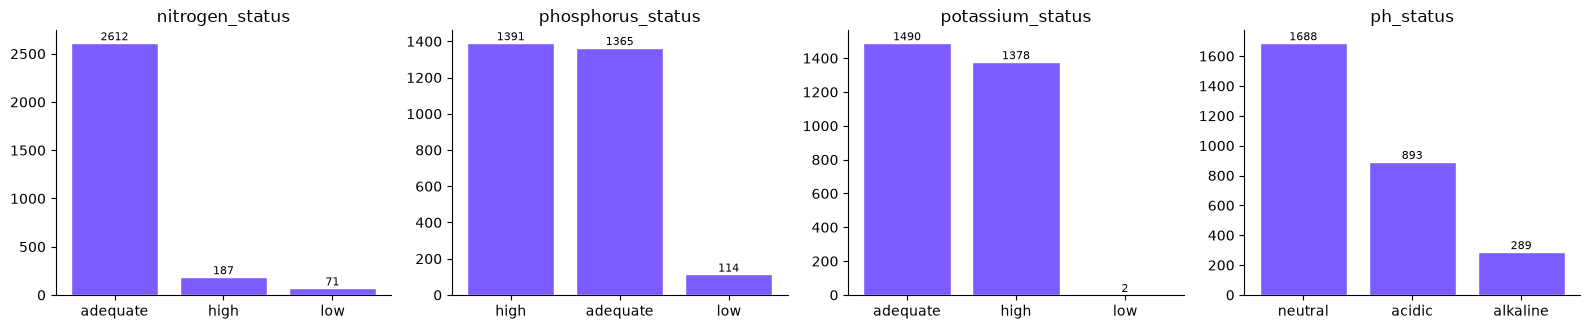

Fertilizer class balance (these are REAL labels, not derived):
fertilizer
DAP                           928
Water Retaining Fertilizer    675
Compost                       337
Muriate of Potash             277
Lime                          176
Balanced NPK Fertilizer       157
Urea                          144
Organic Fertilizer             95
Gypsum                         50
General Purpose Fertilizer     31


In [11]:
targets = ["nitrogen_status", "phosphorus_status", "potassium_status", "ph_status"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, targets):
    counts = df[col].value_counts()
    bars = ax.bar(counts.index, counts.values, color="#7c5cff", edgecolor="white")
    ax.set_title(col)
    ax.spines[["top", "right"]].set_visible(False)
    # Annotate counts so a near-empty class is impossible to miss.
    for b, v in zip(bars, counts.values):
        ax.text(
            b.get_x() + b.get_width() / 2, v, str(v),
            ha="center", va="bottom", fontsize=8,
        )

plt.tight_layout()
plt.show()

print("Fertilizer class balance (these are REAL labels, not derived):")
print(df["fertilizer"].value_counts().to_string())

## 9. Training Function

One reusable trainer for all five models, so hyperparameters and evaluation stay identical
across targets.

Two details worth noting — both added after they caused real failures during development:

* **`labels=` is passed explicitly** to `classification_report` and `f1_score`. A rare class
  (potassium `low`) can be absent from the test split entirely. Without explicit labels,
  `classification_report` raises a length-mismatch error, and `f1_score` silently averages
  over only the classes that happen to be present — inflating the macro score.
* **`class_support` is computed over the full dataset**, not the test split, so rare classes
  remain visible in the saved metrics rather than vanishing at 0.

In [12]:
def _make_clf(num_class: int) -> xgb.XGBClassifier:
    # Shared hyperparameters. max_depth=5 is modest: the decision surface for a threshold
    # rule is simple, and the fertilizer target has only ~2.9k rows, so deeper trees would
    # mostly memorise. tree_method="hist" is the fast histogram builder.
    return xgb.XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.1,
        subsample=0.9,           # row sampling per tree -- mild regularisation
        colsample_bytree=0.9,    # column sampling per tree
        objective="multi:softprob" if num_class > 2 else "binary:logistic",
        num_class=num_class if num_class > 2 else None,
        eval_metric="mlogloss" if num_class > 2 else "logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )


def train_target(df, target_col, label, plot_cm=False):
    # Train one classifier on the canonical feature set and report its metrics.
    X = df[FEATURES]

    # XGBoost needs integer targets, so encode the string classes.
    encoder = LabelEncoder()
    y = encoder.fit_transform(df[target_col])

    # Stratify to preserve class ratios -- but stratification requires >= 2 rows per class,
    # which potassium "low" violates, so fall back to a plain split in that case.
    stratify = y if np.bincount(y).min() >= 2 else None
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=stratify
    )

    model = _make_clf(len(encoder.classes_))
    model.fit(X_train, y_train, verbose=False)

    y_pred = model.predict(X_test)
    all_idx = list(range(len(encoder.classes_)))

    metrics = {
        "classes": list(encoder.classes_),
        "n_train": int(len(X_train)),
        "n_test": int(len(X_test)),
        "accuracy": round(float(accuracy_score(y_test, y_pred)), 4),
        # labels=all_idx keeps the macro average honest when a class is missing from y_test.
        "f1_macro": round(
            float(
                f1_score(
                    y_test, y_pred, labels=all_idx, average="macro", zero_division=0
                )
            ),
            4,
        ),
        # Support over the FULL dataset -- exposes rare classes with unreliable metrics.
        "class_support": {
            str(c): int((y == i).sum()) for i, c in enumerate(encoder.classes_)
        },
    }

    print(f"\n--- {label} ---")
    print(f"  classes  : {list(encoder.classes_)}")
    print(
        f"  accuracy : {metrics['accuracy']:.4f}   "
        f"f1_macro: {metrics['f1_macro']:.4f}"
    )
    print(
        classification_report(
            y_test,
            y_pred,
            labels=all_idx,
            target_names=[str(c) for c in encoder.classes_],
            zero_division=0,
        )
    )

    if plot_cm:
        cm = confusion_matrix(y_test, y_pred, labels=all_idx)
        n = len(encoder.classes_)
        fig, ax = plt.subplots(figsize=(max(5, n * 0.8), max(4, n * 0.7)))
        im = ax.imshow(cm, cmap="Blues")
        ax.set_xticks(range(n), encoder.classes_, rotation=45, ha="right")
        ax.set_yticks(range(n), encoder.classes_)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
        ax.set_title(f"{label} — confusion matrix")
        thresh = cm.max() / 2 if cm.max() else 0
        for i in range(n):
            for j in range(n):
                ax.text(
                    j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > thresh else "black",
                )
        fig.colorbar(im, shrink=0.8)
        plt.tight_layout()
        plt.show()

    return model, encoder, metrics

## 10. Train the Deficiency Classifiers

Documentation deliverable: *"gradient-boosted classification model ... to predict nutrient
deficiency categories."*

Four separate models — one per nutrient plus pH — rather than one multi-output model, because
each nutrient has its own class set and its own threshold band, and a farmer needs to see
which *specific* nutrient is deficient.

Expect ~99% on all four. Read section 8 again if that looks like a win.

In [13]:
metrics = {}
deficiency_encoders = {}

# NPK share the same low/adequate/high class structure.
for nutrient, short in (("nitrogen", "n"), ("phosphorus", "p"), ("potassium", "k")):
    model, enc, m = train_target(df, f"{nutrient}_status", f"deficiency: {nutrient}")
    model.save_model(MODELS_DIR / f"deficiency_{short}_xgb.json")
    deficiency_encoders[nutrient] = enc
    metrics[f"deficiency_{nutrient}"] = m

# pH is separate: its classes are acidic/neutral/alkaline, not low/adequate/high.
model, enc, m = train_target(df, "ph_status", "deficiency: pH")
model.save_model(MODELS_DIR / "deficiency_ph_xgb.json")
deficiency_encoders["ph"] = enc
metrics["deficiency_ph"] = m

# One joblib file holding all four encoders, keyed by nutrient.
joblib.dump(deficiency_encoders, MODELS_DIR / "deficiency_label_encoders.joblib")
print("\nSaved 4 deficiency models + label encoders.")


--- deficiency: nitrogen ---
  classes  : ['adequate', 'high', 'low']
  accuracy : 0.9948   f1_macro: 0.9724
              precision    recall  f1-score   support

    adequate       1.00      0.99      1.00       523
        high       0.97      1.00      0.99        37
         low       0.88      1.00      0.93        14

    accuracy                           0.99       574
   macro avg       0.95      1.00      0.97       574
weighted avg       1.00      0.99      0.99       574




--- deficiency: phosphorus ---
  classes  : ['adequate', 'high', 'low']
  accuracy : 0.9983   f1_macro: 0.9988
              precision    recall  f1-score   support

    adequate       1.00      1.00      1.00       273
        high       1.00      1.00      1.00       278
         low       1.00      1.00      1.00        23

    accuracy                           1.00       574
   macro avg       1.00      1.00      1.00       574
weighted avg       1.00      1.00      1.00       574




--- deficiency: potassium ---
  classes  : ['adequate', 'high', 'low']
  accuracy : 0.9983   f1_macro: 0.6655
              precision    recall  f1-score   support

    adequate       1.00      1.00      1.00       298
        high       1.00      1.00      1.00       276
         low       0.00      0.00      0.00         0

    accuracy                           1.00       574
   macro avg       0.67      0.67      0.67       574
weighted avg       1.00      1.00      1.00       574




--- deficiency: pH ---
  classes  : ['acidic', 'alkaline', 'neutral']
  accuracy : 0.9983   f1_macro: 0.9966
              precision    recall  f1-score   support

      acidic       1.00      1.00      1.00       179
    alkaline       1.00      0.98      0.99        58
     neutral       1.00      1.00      1.00       337

    accuracy                           1.00       574
   macro avg       1.00      0.99      1.00       574
weighted avg       1.00      1.00      1.00       574


Saved 4 deficiency models + label encoders.


## 11. Train the Fertilizer Advisory Model

**This is the model that actually matters.** Its 10 classes come from the dataset's own
`Fertilizer` column, so the score reflects real predictive skill rather than rule recovery.

The confusion matrix is worth reading closely: errors concentrate in the low-support classes
(`General Purpose Fertilizer`, `Organic Fertilizer`), which is the expected failure mode when
a class has only a few dozen examples.


--- fertilizer advisory ---
  classes  : ['Balanced NPK Fertilizer', 'Compost', 'DAP', 'General Purpose Fertilizer', 'Gypsum', 'Lime', 'Muriate of Potash', 'Organic Fertilizer', 'Urea', 'Water Retaining Fertilizer']
  accuracy : 0.9791   f1_macro: 0.9204
                            precision    recall  f1-score   support

   Balanced NPK Fertilizer       0.88      0.91      0.89        32
                   Compost       1.00      1.00      1.00        67
                       DAP       0.99      1.00      1.00       186
General Purpose Fertilizer       0.75      0.50      0.60         6
                    Gypsum       1.00      1.00      1.00        10
                      Lime       1.00      1.00      1.00        35
         Muriate of Potash       1.00      1.00      1.00        55
        Organic Fertilizer       0.70      0.74      0.72        19
                      Urea       1.00      1.00      1.00        29
Water Retaining Fertilizer       1.00      0.99      1.00      

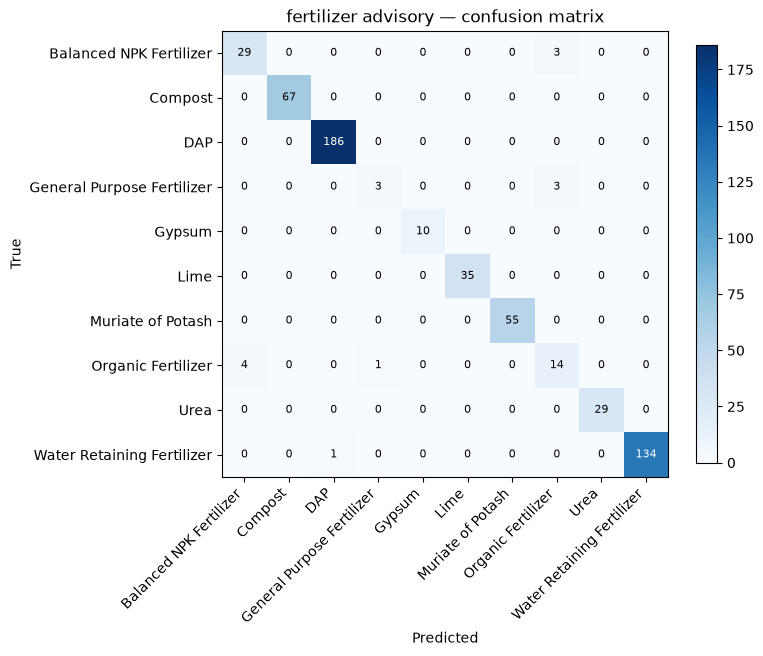

Saved fertilizer model + label encoder.


In [14]:
fert_model, fert_enc, fert_metrics = train_target(
    df, "fertilizer", "fertilizer advisory", plot_cm=True
)

fert_model.save_model(MODELS_DIR / "fertilizer_xgb.json")
joblib.dump(fert_enc, MODELS_DIR / "fertilizer_label_encoder.joblib")
metrics["fertilizer"] = fert_metrics

print("Saved fertilizer model + label encoder.")

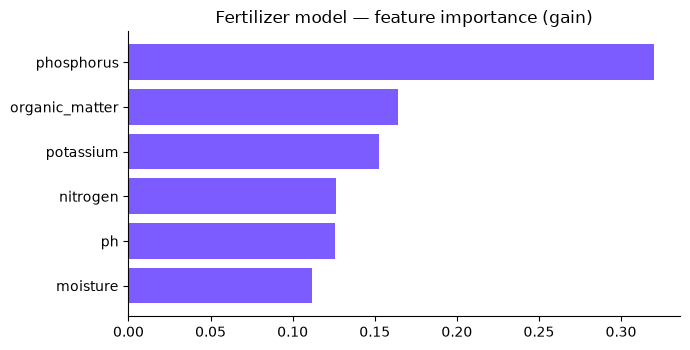

In [15]:
# Gain-based feature importance: which parameters drive the fertilizer choice.
# For per-prediction attributions the API uses SHAP instead -- see
# backend/app/ml/structured.py, which builds a TreeExplainer over this same model.
importance = pd.Series(
    fert_model.feature_importances_, index=FEATURES
).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(importance.index, importance.values, color="#7c5cff")
ax.set_title("Fertilizer model — feature importance (gain)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 12. Fertilizer → Advisory Text

Each fertilizer maps 1:1 to a farmer-facing `Remark` in the dataset. This lookup becomes
`fertilizer_recommendation.advisory` in the `POST /analyze` response — the text the Phase 3
PWA reads aloud in Hindi or Kannada via Sarvam AI.

Storing it as a plain JSON map keeps the advisory text out of the model artifact, so wording
can be corrected or translated without retraining.

In [16]:
# groupby().first() is safe here because the mapping is 1:1 -- verified by checking that
# each fertilizer has exactly one distinct remark.
assert df.groupby("fertilizer")["remark"].nunique().max() == 1, "remark mapping is not 1:1"

remarks = df.groupby("fertilizer")["remark"].first().to_dict()
(MODELS_DIR / "fertilizer_remarks.json").write_text(
    json.dumps(remarks, indent=2), encoding="utf-8"
)

for fert, text in remarks.items():
    print(f"  {fert:<28} {text[:68]}...")

  Balanced NPK Fertilizer      Provides a balanced mix of nitrogen, phosphorus, and potassium for l...
  Compost                      Enhances organic matter and improves soil structure. Prefer this for...
  DAP                          Rich in phosphorus, essential for root development. Prefer this for ...
  General Purpose Fertilizer   Suitable for general use across various soil and crop types. Prefer ...
  Gypsum                       Corrects alkaline soil, adds calcium and sulfur. Prefer this to lowe...
  Lime                         Neutralizes acidic soil and improves pH balance. Prefer this to corr...
  Muriate of Potash            High potassium content, improves fruit and flower quality. Prefer th...
  Organic Fertilizer           Enhances fertility naturally, ideal for peaty soils. Prefer this to ...
  Urea                         Provides high nitrogen, ideal for rapid leafy growth. Prefer this fo...
  Water Retaining Fertilizer   Improves water retention in dry soils. Pre

## 13. Save Model Metadata

`structured_model_meta.json` is the **contract between training and inference**. It carries:

* `feature_order` — so the API builds its input row in the right order
* `thresholds` / `ph_bands` — so the rule engine matches what the labels were derived from
* `feature_medians` — used to impute parameters a farmer leaves blank on the form
* `metrics` including `class_support` — so rare-class weakness is inspectable at runtime
* `caveats` — so the limitations travel *with the artifacts*, not just in this notebook

In [17]:
meta = {
    "feature_order": FEATURES,
    "feature_units": {
        "nitrogen": "kg/ha",
        "phosphorus": "kg/ha",
        "potassium": "kg/ha",
        "ph": "0-14",
        "organic_matter": "%",
        "moisture": "%",
    },
    "thresholds": THRESHOLDS,
    # Used by the inference service to impute parameters a farmer leaves blank.
    "feature_medians": {f: round(float(df[f].median()), 4) for f in FEATURES},
    "ph_bands": {
        "acidic": f"< {PH_BANDS['acidic']}",
        "neutral": f"{PH_BANDS['acidic']} - {PH_BANDS['alkaline']}",
        "alkaline": f"> {PH_BANDS['alkaline']}",
    },
    "training_data": {"source": DATA_PATH.name, **clean_report},
    "metrics": metrics,
    "caveats": [
        "Deficiency labels are DERIVED from the threshold bands above, not ground "
        "truth. Their near-perfect accuracy reflects rule consistency, not "
        "predictive skill. The rule engine remains the source of truth; these "
        "models add calibrated probabilities and SHAP attributions.",
        "The fertilizer model uses real dataset labels and is genuinely predictive.",
        "Thresholds are provisional. Calibrate against ICAR Soil Health Card "
        "reference bands for the target region before advisory use.",
    ],
    "random_state": RANDOM_STATE,
}

(MODELS_DIR / "structured_model_meta.json").write_text(
    json.dumps(meta, indent=2), encoding="utf-8"
)

print(json.dumps(meta, indent=2)[:1100], "\n...")

{
  "feature_order": [
    "nitrogen",
    "phosphorus",
    "potassium",
    "ph",
    "organic_matter",
    "moisture"
  ],
  "feature_units": {
    "nitrogen": "kg/ha",
    "phosphorus": "kg/ha",
    "potassium": "kg/ha",
    "ph": "0-14",
    "organic_matter": "%",
    "moisture": "%"
  },
  "thresholds": {
    "nitrogen": {
      "low": 40.0,
      "high": 80.0
    },
    "phosphorus": {
      "low": 30.0,
      "high": 60.0
    },
    "potassium": {
      "low": 30.0,
      "high": 60.0
    }
  },
  "feature_medians": {
    "nitrogen": 59.4296,
    "phosphorus": 58.8479,
    "potassium": 59.136,
    "ph": 6.3382,
    "organic_matter": 1.4868,
    "moisture": 60.0335
  },
  "ph_bands": {
    "acidic": "< 6.0",
    "neutral": "6.0 - 7.5",
    "alkaline": "> 7.5"
  },
  "training_data": {
    "source": "fertilizer_recommendation.csv",
    "rows_raw": 3100,
    "rows_after_cleaning": 2870,
    "rows_dropped": 230,
    "drop_reason": "negative nutrient/carbon values or out-of-range pH

## 14. Artifact Summary

In [18]:
print(f"{'artifact':<40}{'bytes':>12}")
print("-" * 52)
total = 0
for f in sorted(MODELS_DIR.iterdir()):
    if f.is_file():
        total += f.stat().st_size
        print(f"  {f.name:<38}{f.stat().st_size:>12,}")
print("-" * 52)
print(f"  {'total':<38}{total:>12,}")

print("\nEvaluation summary")
print(f"{'model':<26}{'accuracy':>10}{'f1_macro':>10}   class support")
for k, v in metrics.items():
    print(
        f"  {k:<24}{v['accuracy']:>10.4f}{v['f1_macro']:>10.4f}   "
        f"{v['class_support']}"
    )

artifact                                       bytes
----------------------------------------------------
  deficiency_k_xgb.json                      580,964
  deficiency_label_encoders.joblib             1,247
  deficiency_n_xgb.json                      585,300
  deficiency_p_xgb.json                      628,672
  deficiency_ph_xgb.json                     655,558
  fertilizer_label_encoder.joblib                637
  fertilizer_remarks.json                      1,482
  fertilizer_xgb.json                      2,348,114
  structured_model_meta.json                   3,700
----------------------------------------------------
  total                                    4,805,674

Evaluation summary
model                       accuracy  f1_macro   class support
  deficiency_nitrogen         0.9948    0.9724   {'adequate': 2612, 'high': 187, 'low': 71}
  deficiency_phosphorus       0.9983    0.9988   {'adequate': 1365, 'high': 1391, 'low': 114}
  deficiency_potassium        0.9983    0.

## 15. Inference Smoke Test

Reload the artifacts **from disk** — not the in-memory objects — and check a deficient sample
and a healthy sample. This is what catches a broken `save_model` or a mismatched encoder
before the API does.

Each model prediction is compared against the authoritative rule. A `DIFF` means the reading
sits near a threshold boundary; at inference the rule wins and the disagreement is reported
in the response's `model_agreement` field.

In [19]:
# Reload strictly from disk to verify the saved artifacts are usable.
loaded = {}
for nutrient, short in (
    ("nitrogen", "n"), ("phosphorus", "p"), ("potassium", "k"), ("ph", "ph")
):
    m = xgb.XGBClassifier()
    m.load_model(MODELS_DIR / f"deficiency_{short}_xgb.json")
    loaded[nutrient] = m

enc = joblib.load(MODELS_DIR / "deficiency_label_encoders.joblib")
fm = xgb.XGBClassifier()
fm.load_model(MODELS_DIR / "fertilizer_xgb.json")
fe = joblib.load(MODELS_DIR / "fertilizer_label_encoder.joblib")

samples = {
    "deficient + acidic": [18, 12, 15, 5.1, 0.4, 15],
    "healthy":            [60, 45, 50, 6.8, 2.0, 45],
}

for name, vals in samples.items():
    row = pd.DataFrame([vals], columns=FEATURES)
    print(f"\n{name}:  {dict(zip(FEATURES, vals))}")

    for nutrient in ("nitrogen", "phosphorus", "potassium", "ph"):
        proba = loaded[nutrient].predict_proba(row)[0]
        idx = int(np.argmax(proba))
        pred = enc[nutrient].classes_[idx]

        # Authoritative rule, for comparison.
        if nutrient == "ph":
            rule = ph_status(row["ph"].iloc[0])
        else:
            t = THRESHOLDS[nutrient]
            rule = nutrient_status(row[nutrient].iloc[0], t["low"], t["high"])

        flag = "OK  " if pred == rule else "DIFF"
        print(
            f"   {flag} {nutrient:<12} rule={rule:<9} "
            f"model={pred:<9} p={proba[idx]:.4f}"
        )

    fp = fm.predict_proba(row)[0]
    fi = int(np.argmax(fp))
    print(f"   ->   fertilizer: {fe.classes_[fi]} (p={fp[fi]:.4f})")
    print(f"        advisory  : {remarks[fe.classes_[fi]][:66]}...")


deficient + acidic:  {'nitrogen': 18, 'phosphorus': 12, 'potassium': 15, 'ph': 5.1, 'organic_matter': 0.4, 'moisture': 15}
   OK   nitrogen     rule=low       model=low       p=0.9846
   OK   phosphorus   rule=low       model=low       p=0.9779
   DIFF potassium    rule=low       model=adequate  p=0.9576
   OK   ph           rule=acidic    model=acidic    p=0.9997
   ->   fertilizer: Urea (p=0.9933)
        advisory  : Provides high nitrogen, ideal for rapid leafy growth. Prefer this ...

healthy:  {'nitrogen': 60, 'phosphorus': 45, 'potassium': 50, 'ph': 6.8, 'organic_matter': 2.0, 'moisture': 45}
   OK   nitrogen     rule=adequate  model=adequate  p=0.9999
   OK   phosphorus   rule=adequate  model=adequate  p=0.9993
   OK   potassium    rule=adequate  model=adequate  p=0.9996
   OK   ph           rule=neutral   model=neutral   p=0.9993
   ->   fertilizer: DAP (p=0.9992)
        advisory  : Rich in phosphorus, essential for root development. Prefer this fo...


## 16. Where This Fits

### Consumed by

`backend/app/models/deficiency_pred.ipynb` loads these artifacts and serves `POST /analyze`, returning
the soil health score, deficiency diagnosis, degradation risk index, and fertilizer advisory
— plus SHAP attributions when the request sets `explain: true`.

### Weeks 3–4 deliverable status

| # | Deliverable | Status |
|---|---|---|
| 1 | CNN — soil type, texture, deficiency symptoms | Needs retrain: train/val leakage, wrong classes |
| 2 | Gradient-boosted deficiency model | **Complete — this notebook** |
| 3 | Hybrid fusion model | Blocked on 1 |
| 4 | Grad-CAM + SHAP | SHAP complete; Grad-CAM blocked on 1 |
| 5 | FastAPI endpoint | Complete — `POST /analyze` |

### Known limitations

1. **Deficiency accuracy is not predictive skill** — derived labels, as explained in
   section 8. The fertilizer model's 97.9% *is* real.
2. **Potassium `low` is untrainable** from this dataset (~2 rows). The threshold rule handles
   it; the model's confidence for that class should be ignored.
3. **Thresholds are uncalibrated** — provisional values pending ICAR Soil Health Card
   reference bands for the target region.
4. **Fusion cannot be jointly trained** — the image and tabular datasets share no sample
   identifiers, so late fusion at inference is the honest approach.
5. **No hyperparameter search or cross-validation** — a single 80/20 split with fixed
   hyperparameters. Adequate for a rule-recovery target; worth revisiting for the fertilizer
   model if its accuracy needs improving.